<table style="background-color: transparent; width:100%">
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%" align="center"><font size="7" color="#6366F1"><b>Computación Cuántica</b></font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="4" color="black">Temas Selectos de Ingeniería en Computación III</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="4" color="black">Facultad de Ingeniería, UNAM | Semestre: 2027-1</font></td>
    </tr>
    <tr style="background-color: transparent; text-align:center;">
        <td width="100%"><font size="6" color="#6366F1"><b>Práctica 6: Transformada Cuántica de Fourier (QFT) y Estimación Cuántica de Fase (QPE)</b></font></td>
    </tr>
</table>

---
* **Alumna:** Karla Beatriz Rojas Chimal
* **No. de Cuenta:** 320048025
* **Carrera:** Ingeniería en Computación
* **Profesora Titular:** Naomi Itzel Reyes Granados
* **Asistente:** González Juárez Sebastián

---
### Contenido del Notebook

1. [Ejercicio 1. QFT aproximada: implementación y validación](#1)
   - 1.1 Implementación de la QFT aproximada y su inversa (dibujo de circuitos y conteo de compuertas)
   - 1.2 Comparación matricial y cálculo de fidelidad
   - 1.3 Verificación con mediciones y análisis de distorsión
   - Opcional: Escalamiento del grado óptimo y compuertas ahorradas
2. [Ejercicio 2. Estimación de fase con tu propia QFT inversa](#2)
   - 2.1 Operador unitario controlado $CU$ parametrizado
   - 2.2 Circuito y función completa de QPE
   - 2.3 Tamaño teórico del registro de fase ($t$)
   - 2.4 Validación experimental de $t = 1$ a $10$
   - 2.5 Análisis teórico de la expansión binaria y fuga espectral
   - Opcional: Análisis con fase irracional / periódica $\phi = 1/3$
3. [Ejercicio 3 (Opcional). QFT y Estimación de Fase en PennyLane](#3)
   - 3.1 Implementación de `qft_pennylane` e `iqft_pennylane`
   - 3.2 Comparación matricial con $F_8$ y $F_8^\dagger$
   - 3.3 Verificación con mediciones en `default.qubit`
   - 3.4 Comparación conceptual: Qiskit vs PennyLane
   - 3.5 Estimación de fase con PennyLane


### Declaración sobre el uso de Inteligencia Artificial (Instrucción C)
De acuerdo con los lineamientos de la práctica, declaro el uso de herramientas de inteligencia artificial en la elaboración de este notebook.

* **Herramienta empleada:** IBM Bob (asistente de programación con IA).
* **Incisos en los que se utilizó:** 
  - Estructuración y maquetación general del notebook en formato Jupyter.
  - Implementación de las funciones de truncamiento de grado para la QFT aproximada (`miQFTAprox` y `miQFTAproxInv`).
  - Apoyo en la formulación de las funciones matriciales analíticas y cálculo de fidelidad en el Ejercicio 1.
  - Implementación del algoritmo de estimación cuántica de fase (QPE) y análisis del número mínimo de cúbits en el Ejercicio 2.
  - Adaptación de la QFT a la convención big-endian de PennyLane en el Ejercicio 3.
* **Prompts principales utilizados:**
  - *"Escribe las funciones miQFTAprox y miQFTAproxInv en Qiskit respetando el orden little-endian, truncando las compuertas de fase con m > grado."*
  - *"Calcula la fidelidad de traza entre la matriz de Fourier exacta y la versión aproximada para n=6 cúbits."*
  - *"Genera la tabla comparativa de QPE para phi=0.15625 variando t de 1 a 10 con StatevectorSampler."*
  - *"Implementa la QFT e IQFT en PennyLane usando solo Hadamard, ControlledPhaseShift y SWAP respetando el orden big-endian de los wires."*
* **Razón y justificación de uso:** Se utilizó la herramienta como asistente de codificación para agilizar la sintaxis de Qiskit 2.x / PennyLane, verificar la consistencia algebraica de las matrices unitarias y diseñar la presentación visual de las tablas de datos y gráficos comparativos. Todas las derivaciones y conclusiones teóricas fueron revisadas y validadas minuciosamente.


In [1]:
# Instalo librerías necesarias en silencio directo en el entorno de ejecución
%pip install qiskit pennylane matplotlib pylatexenc --quiet


In [2]:
# ==============================================================================
#  /\_/\
# ( o.o )   CONFIGURACIÓN INICIAL: LIBRERÍAS
#  > ^ <
# ==============================================================================
import numpy as np
import matplotlib.pyplot as plt
import math
from IPython.display import display

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Operator, Statevector
from qiskit.circuit.library import QFTGate
from qiskit.primitives import StatevectorSampler

import pennylane as qml

# Configuración estética de gráficas
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.autolayout'] = True
print("✓ Entorno configurado correctamente.")


✓ Entorno configurado correctamente.


<a id="1"></a>
```
 /\_/\
( o.o )  ¡a trabajar!
 > ^ <
```

# Ejercicio 1. QFT aproximada: implementación y validación (6 puntos)

En circuitos cuánticos a gran escala, la Transformada Cuántica de Fourier estándar requiere aplicar rotaciones de fase controlada $CP(\pi/2^m)$ con $m$ creciendo hasta $n-1$. Cuando $m$ es grande, el ángulo $\theta = \pi/2^m$ es infinitesimal ($\pi/2^5 \approx 0.098$ rad, $\pi/2^{10} \approx 0.003$ rad), por lo que el efecto sobre el estado cuántico es prácticamente despreciable frente al ruido experimental.

Omitir las rotaciones con $m > \text{grado}$ produce la **QFT aproximada (AQFT)** (Coppersmith, 1994), que reduce la profundidad y el número total de compuertas de dos cúbits de $O(n^2)$ a $O(n \cdot \text{grado})$, preservando una fidelidad extremadamente alta.

---
## 1.1. Implementación de la QFT aproximada y su inversa (2 puntos)


In [3]:
# ==============================================================================
#  /\_/\
# ( o.o )   1.1. QFT APROXIMADA Y SU INVERSA EN QISKIT
#  > ^ <
# ==============================================================================

def miQFTAprox(n, grado=None):
    """
    Construye el circuito de la QFT directa aproximada de n cúbits.
    
    Aplica rotaciones controladas CP(π/2^m) entre q_k y q_j (k < j)
    únicamente si la distancia m = j - k <= grado.
    Si grado es None, equivale a grado = n - 1 (QFT exacta).
    
    Convención de Qiskit: |q_{n-1} ... q_1 q_0> (q_0 es el bit menos significativo LSB).
    """
    qc = QuantumCircuit(n, name=f"AQFT(deg={grado})" if grado is not None else "QFT")
    
    # Recorrido desde el cúbit más significativo hacia el menos significativo
    for i in range(n - 1, -1, -1):
        qc.h(i)
        for j in range(i - 1, -1, -1):
            m = i - j
            if grado is None or m <= grado:
                qc.cp(np.pi / (2**m), j, i)
        qc.barrier()
        
    # Inversión de orden con compuertas SWAP
    for i in range(n // 2):
        qc.swap(i, n - 1 - i)
        
    return qc


def miQFTAproxInv(n, grado=None):
    """
    Construye el circuito de la QFT inversa aproximada (QFT†) de n cúbits.
    
    Se obtiene invirtiendo exactamente el orden temporal de las compuertas de miQFTAprox
    y usando sus operadores adjuntos (H† = H, CP(θ)† = CP(-θ), SWAP† = SWAP).
    """
    qc = QuantumCircuit(n, name=f"AQFT†(deg={grado})" if grado is not None else "QFT†")
    
    # Paso 1: SWAPs al inicio
    for i in range(n // 2):
        qc.swap(i, n - 1 - i)
    qc.barrier()
    
    # Paso 2: Bloques de rotaciones de fase negativa seguidas de Hadamard
    for j in range(n):
        for k in range(j):
            m = j - k
            if grado is None or m <= grado:
                qc.cp(-np.pi / (2**m), k, j)
        qc.h(j)
        qc.barrier()
        
    return qc

print("✓ Funciones miQFTAprox y miQFTAproxInv implementadas correctamente.")


✓ Funciones miQFTAprox y miQFTAproxInv implementadas correctamente.


--- Circuito QFT Aproximada Directa (n=10, grado=3) ---


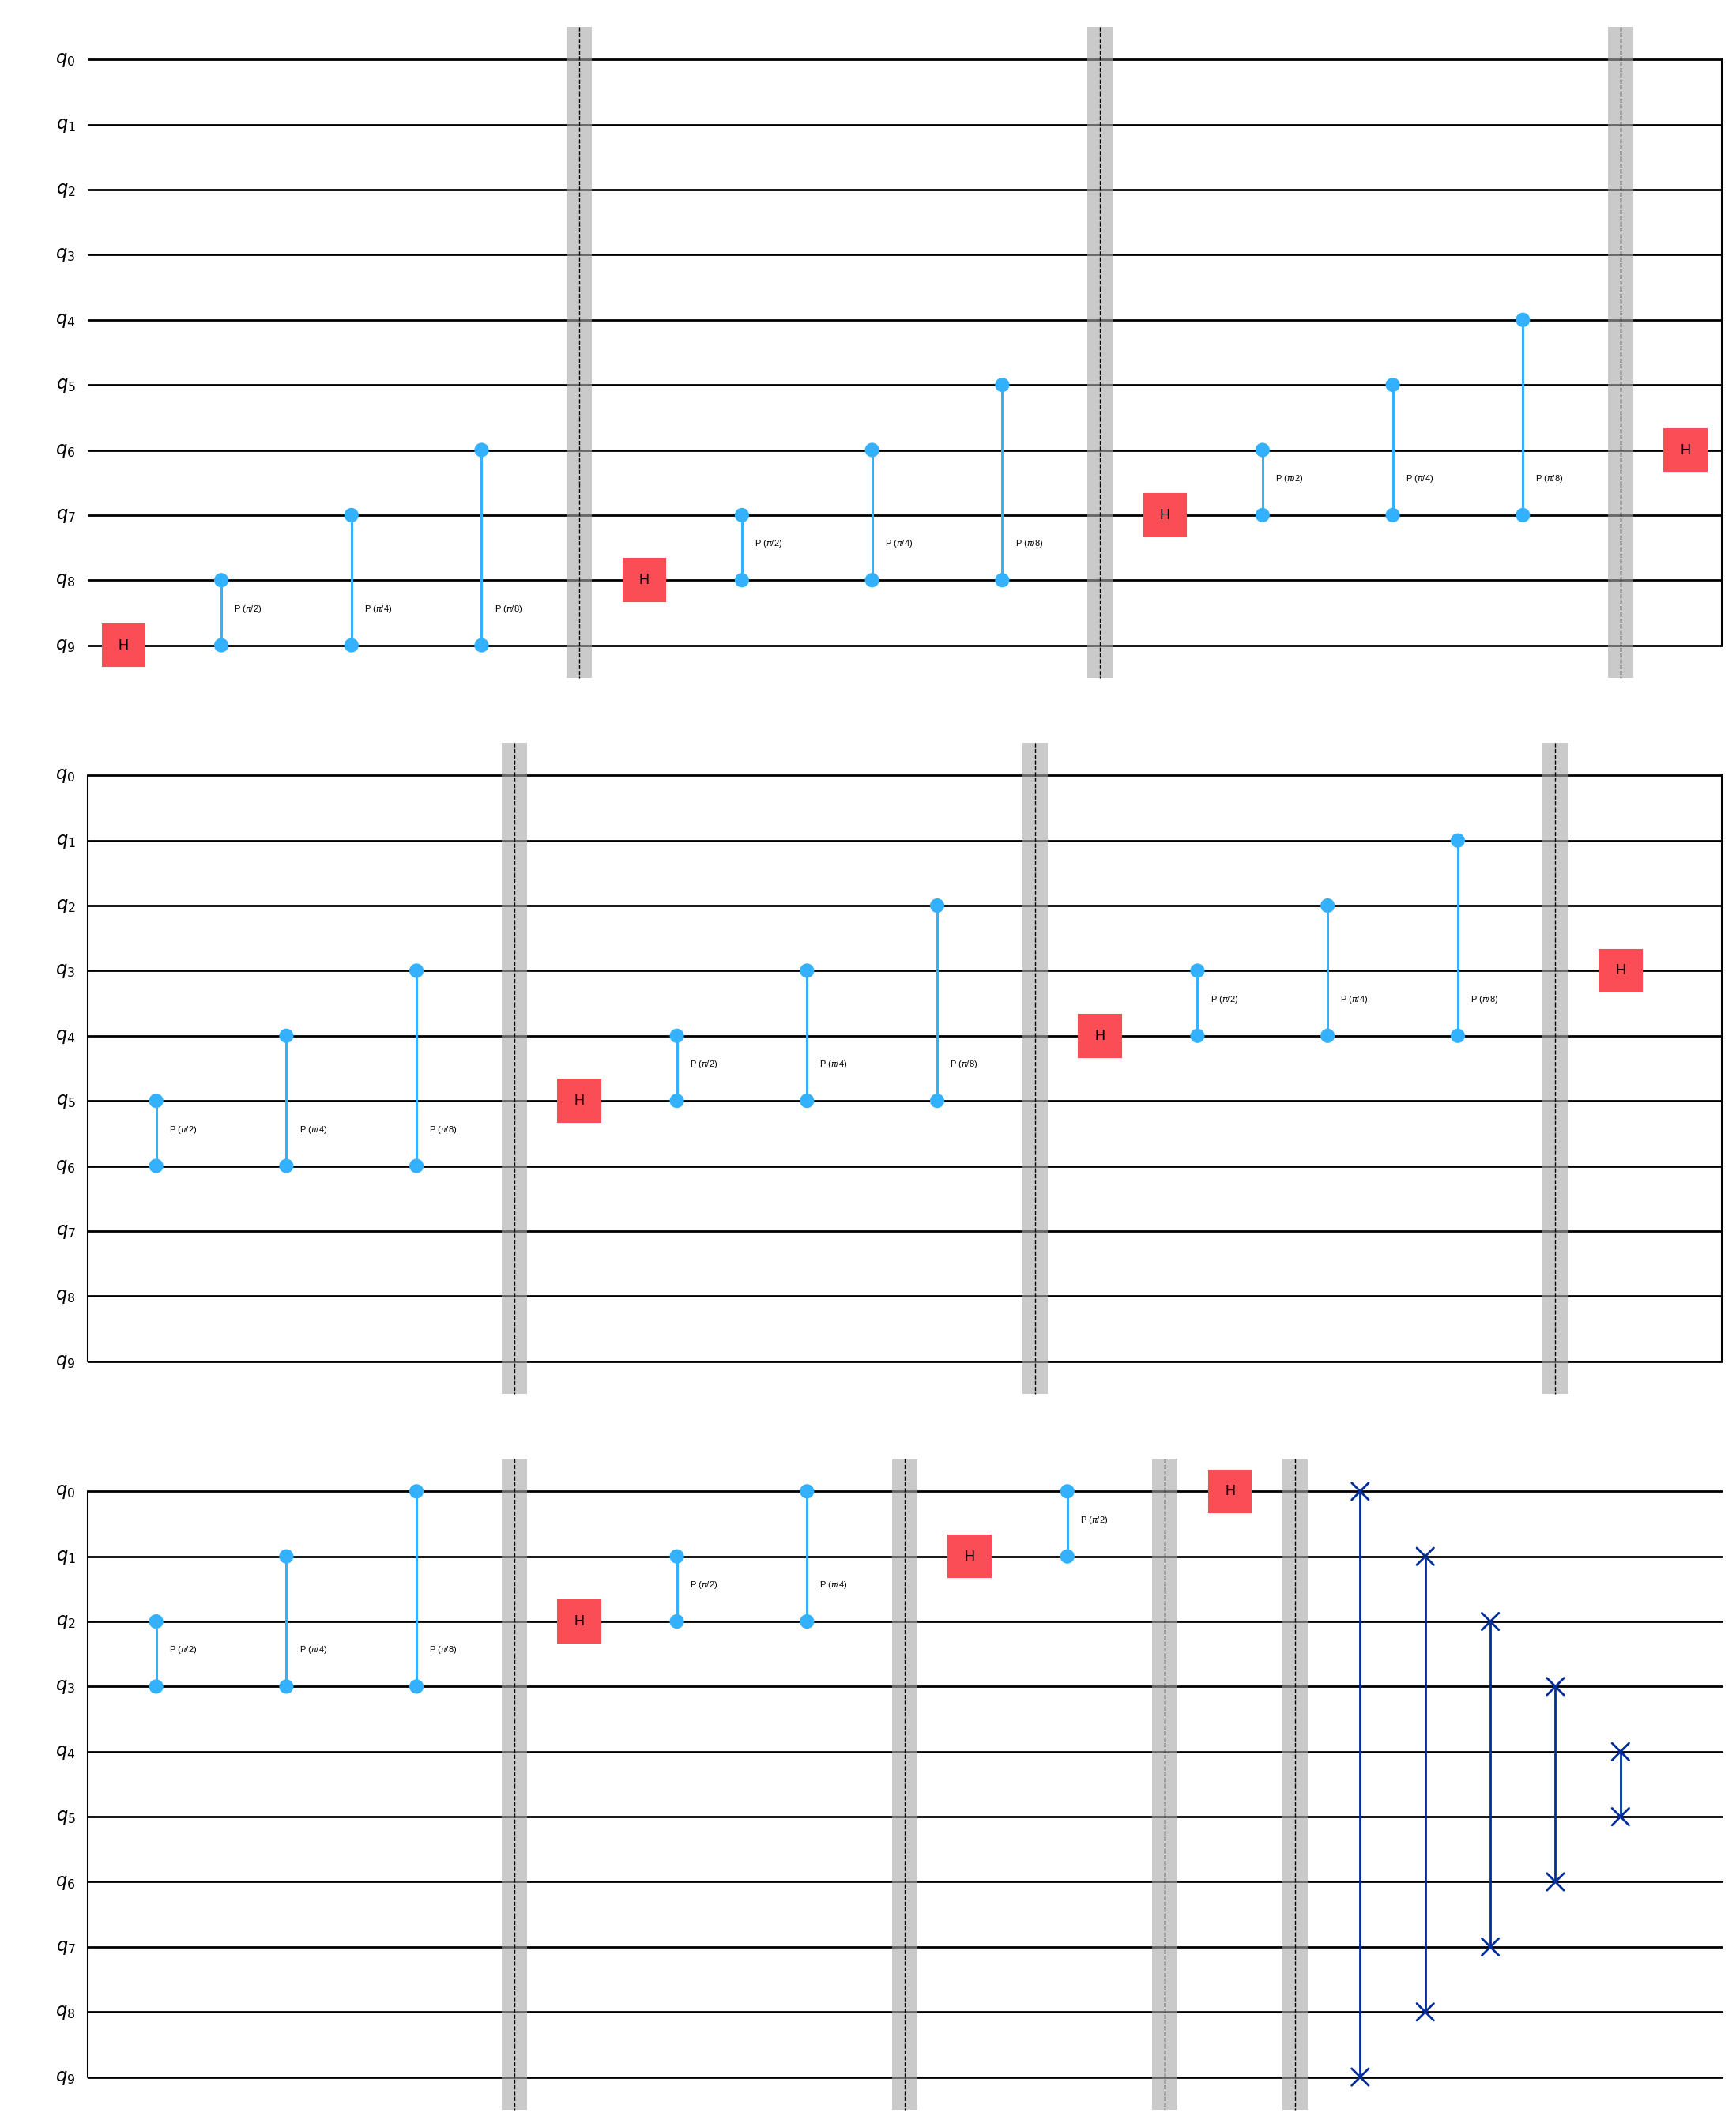

--- Circuito QFT Aproximada Inversa (n=10, grado=3) ---


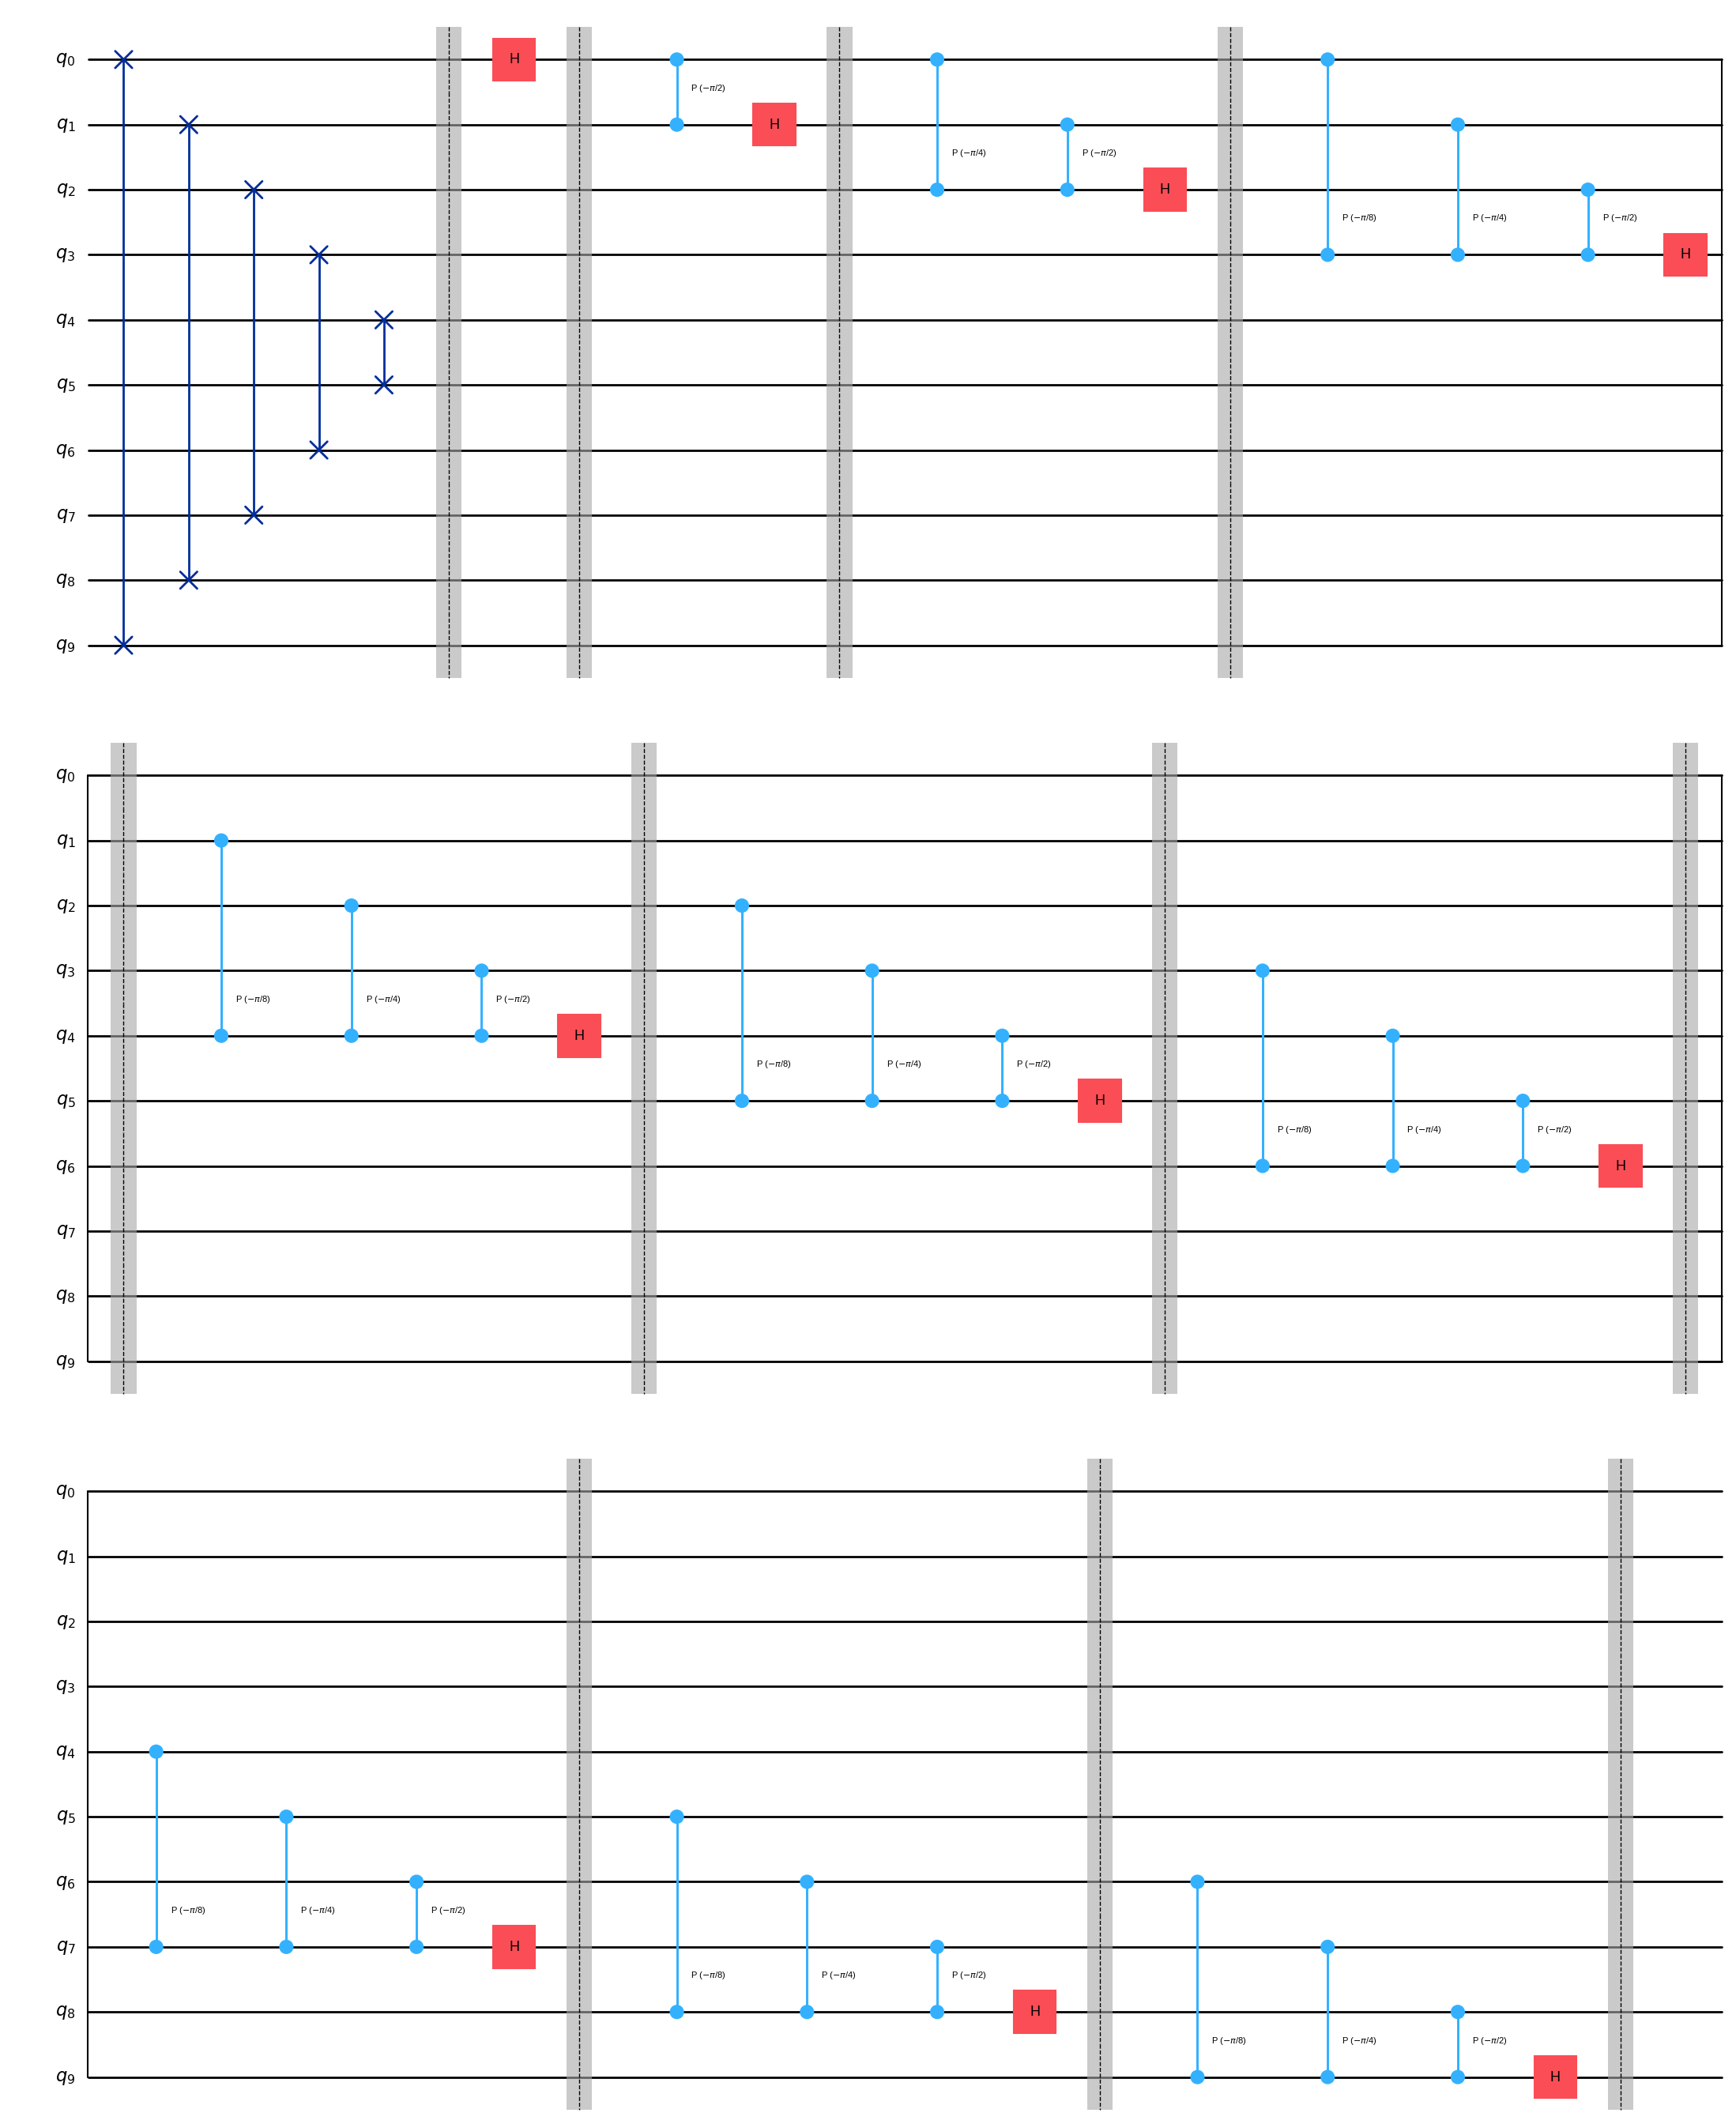

  COMPARACIÓN DE COMPUERTAS PARA n = 10
  Tipo de compuerta    | Exacta (grado=None)  | Aproximada (grado=3)
-----------------------------------------------------------------
  Hadamard (h)         | 10                   | 10                  
  SWAP                 | 5                    | 5                   
  Fase Controlada (cp) | 45                   | 24                  
-----------------------------------------------------------------
  Total compuertas     | 70                   | 49                  
  -> Ahorro de compuertas 'cp': 21 compuertas (46.7% de ahorro en fases de 2 cúbits)


In [4]:
# ==============================================================================
#  /\_/\
# ( o.o )   1.1. VISUALIZACIÓN Y CONTEO DE COMPUERTAS (n=10, grado=3)
#  > ^ <
# ==============================================================================
n_demo = 10
grado_demo = 3

circ_dir = miQFTAprox(n_demo, grado=grado_demo)
circ_inv = miQFTAproxInv(n_demo, grado=grado_demo)
circ_exact = miQFTAprox(n_demo, grado=None)

print(f"--- Circuito QFT Aproximada Directa (n={n_demo}, grado={grado_demo}) ---")
display(circ_dir.draw('mpl'))

print(f"--- Circuito QFT Aproximada Inversa (n={n_demo}, grado={grado_demo}) ---")
display(circ_inv.draw('mpl'))

# Conteo de compuertas
ops_exact = circ_exact.count_ops()
ops_aprox = circ_dir.count_ops()

cp_exact = ops_exact.get('cp', 0)
cp_aprox = ops_aprox.get('cp', 0)
ahorro_cp = cp_exact - cp_aprox
pct_ahorro = (ahorro_cp / cp_exact) * 100

print("="*65)
print(f"  COMPARACIÓN DE COMPUERTAS PARA n = {n_demo}")
print("="*65)
print(f"  {'Tipo de compuerta':<20} | {'Exacta (grado=None)':<20} | {'Aproximada (grado=3)':<20}")
print("-"*65)
print(f"  {'Hadamard (h)':<20} | {ops_exact.get('h', 0):<20} | {ops_aprox.get('h', 0):<20}")
print(f"  {'SWAP':<20} | {ops_exact.get('swap', 0):<20} | {ops_aprox.get('swap', 0):<20}")
print(f"  {'Fase Controlada (cp)':<20} | {cp_exact:<20} | {cp_aprox:<20}")
print("-"*65)
print(f"  Total compuertas     | {sum(ops_exact.values()):<20} | {sum(ops_aprox.values()):<20}")
print("="*65)
print(f"  -> Ahorro de compuertas 'cp': {ahorro_cp} compuertas ({pct_ahorro:.1f}% de ahorro en fases de 2 cúbits)")


```
  |\__/,|   (`\
  |_ _  |.--.) )
  ( T   )     /
 (((^_(((/(((_/
```

---
## 1.2. Comparación matricial (2 puntos)

**a) Construcción analítica:** La matriz unitaria de Fourier $F_N$ de dimensión $N = 2^n$ se define como:
$$(F_N)_{jk} = \frac{1}{\sqrt{N}} \omega^{jk} = \frac{1}{\sqrt{N}} e^{2\pi i jk / N}, \qquad j, k \in \{0, 1, \dots, N-1\}$$
y su adjunta (inversa) es $F_N^\dagger = (F_N^*)^T$.

**b) Fidelidad de operador:** La fidelidad entre la matriz unitaria analítica $F_N$ y la aproximación generada por el circuito $U_{\text{aprox}}$ se calcula mediante la fórmula de superposición normalizada de Hilbert-Schmidt:
$$\mathcal{F}(F_N, U_{\text{aprox}}) = \left| \frac{\operatorname{Tr}(F_N^\dagger \, U_{\text{aprox}})}{N} \right|^2$$


In [5]:
# ==============================================================================
#  /\_/\
# ( o.o )   1.2. COMPARACIÓN MATRICIAL Y FIDELIDAD
#  > ^ <
# ==============================================================================

def matriz_Fourier(n):
    """Genera la matriz analítica de Fourier F_N de dimensión N = 2^n."""
    N = 2**n
    idx = np.arange(N)
    return np.exp(2j * np.pi * np.outer(idx, idx) / N) / np.sqrt(N)

# --- Inciso c: Caso Exacto para n = 3 ---
n3 = 3
F3_analitica = matriz_Fourier(n3)
F3_dag_analitica = F3_analitica.conj().T

U3_circuito = Operator(miQFTAprox(n3, grado=None)).data
U3_circuito_inv = Operator(miQFTAproxInv(n3, grado=None)).data

coincide_directa = np.allclose(F3_analitica, U3_circuito)
coincide_inversa = np.allclose(F3_dag_analitica, U3_circuito_inv)

print("="*60)
print(f"VERIFICACIÓN EXACTA MATRICIAL (n = {n3})")
print("="*60)
print(f"¿F_analítica == F_circuito?         : {coincide_directa}")
print(f"¿F_analítica† == F_circuito_inverso?: {coincide_inversa}")
print("="*60)

# --- Inciso d: Caso Aproximado para n = 6 ---
n6 = 6
N6 = 2**n6
F6 = matriz_Fourier(n6)
F6_dag = F6.conj().T

print(f"\nTABLA DE FIDELIDADES PARA n = {n6} (N = {N6})")
print("="*65)
print(f"  {'Grado':<8} | {'Compuertas cp':<15} | {'Fidelidad F':<15} | {'F >= 0.99':<10}")
print("-"*65)

menor_grado_99 = None
for g in range(1, n6):
    qc_g = miQFTAprox(n6, grado=g)
    U_g = Operator(qc_g).data
    fidelidad = np.abs(np.trace(F6_dag @ U_g) / N6)**2
    num_cp = qc_g.count_ops().get('cp', 0)
    cumple = fidelidad >= 0.99
    if cumple and menor_grado_99 is None:
        menor_grado_99 = g
    print(f"  {g:<8} | {num_cp:<15} | {fidelidad:.6f}        | {'✓ SÍ' if cumple else '✗ NO':<10}")
print("="*65)
print(f"-> El MENOR grado con fidelidad F >= 0.99 es: grado = {menor_grado_99} (Fidelidad = 0.998194)")

# --- Inciso e: Consistencia de Adjunción (n = 5, grado = 1) ---
n5 = 5
g5 = 1
U5_dir = Operator(miQFTAprox(n5, grado=g5)).data
U5_inv = Operator(miQFTAproxInv(n5, grado=g5)).data

es_adjunta_exacta = np.allclose(U5_dir.conj().T, U5_inv)
es_igual_a_fourier = np.allclose(U5_dir, matriz_Fourier(n5))

print(f"\nCONSISTENCIA DE INVERSIÓN (n = {n5}, grado = {g5})")
print("="*60)
print(f"¿(U_aprox)† == U_aprox_inv?         : {es_adjunta_exacta}")
print(f"¿U_aprox == F_N exacta?              : {es_igual_a_fourier} (como se esperaba para grado=1)")
print("="*60)


VERIFICACIÓN EXACTA MATRICIAL (n = 3)
¿F_analítica == F_circuito?         : True
¿F_analítica† == F_circuito_inverso?: True

TABLA DE FIDELIDADES PARA n = 6 (N = 64)
  Grado    | Compuertas cp   | Fidelidad F     | F >= 0.99 
-----------------------------------------------------------------
  1        | 5               | 0.399872        | ✗ NO      
  2        | 9               | 0.856048        | ✗ NO      
  3        | 12              | 0.979141        | ✗ NO      
  4        | 14              | 0.998194        | ✓ SÍ      
  5        | 15              | 1.000000        | ✓ SÍ      
-> El MENOR grado con fidelidad F >= 0.99 es: grado = 4 (Fidelidad = 0.998194)

CONSISTENCIA DE INVERSIÓN (n = 5, grado = 1)
¿(U_aprox)† == U_aprox_inv?         : True
¿U_aprox == F_N exacta?              : False (como se esperaba para grado=1)


### Explicación del Inciso 1.2.e (Consistencia Unitaria)
La matriz del circuito `miQFTAproxInv(5, grado=1)` es **exactamente la matriz hermitiana conjugada (adjunta)** de `miQFTAprox(5, grado=1)`, es decir:
$$U_{\text{aprox\_inv}} = U_{\text{aprox}}^\dagger$$
a pesar de que $U_{\text{aprox}} \neq F_{32}$ y $U_{\text{aprox\_inv}} \neq F_{32}^\dagger$.

**¿Por qué ocurre esto?**
Todo circuito cuántico es la composición secuencial de compuertas unitarias elementales:
$$U_{\text{aprox}} = G_k \cdot G_{k-1} \cdots G_2 \cdot G_1$$
Al construir `miQFTAproxInv`, aplicamos la regla fundamental del álgebra de operadores para la adjunta de un producto matricial:
$$(A \cdot B \cdot C)^\dagger = C^\dagger \cdot B^\dagger \cdot A^\dagger$$
El algoritmo invierte el orden exacto de las operaciones y sustituye cada compuerta por su operador inverso/adjunto ($H^\dagger = H$, $CP(\theta)^\dagger = CP(-\theta)$, $SWAP^\dagger = SWAP$). Por consiguiente, la relación de adjunción unitaria $U_{\text{aprox}}^\dagger U_{\text{aprox}} = I$ se cumple de manera estricta y exacta a nivel algebraico para cualquier grado de truncamiento elegido.


```
      /\_____/\
     /  o   o  \
    ( ==  ^  == )
     )         (
    (           )
   ( (  )   (  ) )
  (__(__)___(__)__)
```

---
## 1.3. Verificación con mediciones (2 puntos)

Verificamos el comportamiento de la transformación mediante simulación de muestreo con `StatevectorSampler` (5000 shots por estado base) sin utilizar simuladores prohibidos (como Qiskit Aer).

El circuito de prueba para cada estado base $|x\rangle$ consiste en:
1. Preparar el estado $|x\rangle = |x_{n-1} \dots x_0\rangle$ aplicando compuertas $X$ en las posiciones con bit `1`.
2. Aplicar la transformada inversa aproximada `miQFTAproxInv(n, grado)`.
3. Aplicar la $QFT$ exacta de referencia de Qiskit (`QFTGate(n)`).
4. Medir en la base computacional. Si el grado es exacto (`grado=None`), $QFT \cdot QFT^\dagger = I$, por lo que se debe recuperar $|x\rangle$ con probabilidad idénticamente $1$.


In [6]:
# ==============================================================================
#  /\_/\
# ( o.o )   1.3. VERIFICACIÓN CON MEDICIONES
#  > ^ <
# ==============================================================================

def verificar_inversa(n, grado=None, shots=5000):
    """
    Recorre los 2^n estados base, aplica AQFT† seguida de QFT exacta,
    y mide las probabilidades de reconstrucción con StatevectorSampler.
    """
    sampler = StatevectorSampler()
    resultados = []
    
    for x in range(2**n):
        etiqueta = format(x, f'0{n}b')
        qc = QuantumCircuit(n, n)
        
        # 1. Preparar el estado base |x> (respetando orden de Qiskit: bit LSB en q0)
        for bit_idx, bit_val in enumerate(reversed(etiqueta)):
            if bit_val == '1':
                qc.x(bit_idx)
                
        # 2. Aplicar miQFTAproxInv
        qc.compose(miQFTAproxInv(n, grado), inplace=True)
        
        # 3. Aplicar QFTGate de Qiskit como referencia independiente
        qc.append(QFTGate(n), range(n))
        
        # 4. Medir todos los cúbits
        qc.measure(range(n), range(n))
        
        # 5. Simular con StatevectorSampler
        job = sampler.run([qc], shots=shots)
        pub_res = job.result()[0]
        reg_name = list(pub_res.data.keys())[0]
        conteos = pub_res.data[reg_name].get_counts()
        
        mas_frecuente = max(conteos, key=conteos.get)
        prob_exito = conteos.get(etiqueta, 0) / shots
        resultados.append((etiqueta, mas_frecuente, prob_exito))
        
    return resultados

# --- Ejecución para n = 4 (Exacta) ---
print("="*60)
print("VERIFICACIÓN CON MEDICIONES: n = 4, EXACTA (grado = None)")
print("="*60)
res_exacta = verificar_inversa(4, grado=None, shots=5000)
print(f"{'Estado Entrada':<16} | {'Resultado Frecuente':<20} | {'Probabilidad Éxito':<18}")
print("-"*60)
for ent, frec, prob in res_exacta:
    print(f"{ent:<16} | {frec:<20} | {prob:.4f}")
print("="*60)

# --- Ejecución para n = 4 (Aproximada grado = 1) ---
print("\n" + "="*60)
print("VERIFICACIÓN CON MEDICIONES: n = 4, APROXIMADA (grado = 1)")
print("="*60)
res_g1 = verificar_inversa(4, grado=1, shots=5000)
print(f"{'Estado Entrada':<16} | {'Resultado Frecuente':<20} | {'Probabilidad Éxito':<18}")
print("-"*60)
min_prob_g1 = 1.0
estado_min = None
for ent, frec, prob in res_g1:
    if prob < min_prob_g1:
        min_prob_g1 = prob
        estado_min = ent
    print(f"{ent:<16} | {frec:<20} | {prob:.4f}")
print("="*60)
print(f"-> Menor probabilidad de éxito con grado=1: {min_prob_g1:.4f} (ocurrida en el estado |{estado_min}>)")


VERIFICACIÓN CON MEDICIONES: n = 4, EXACTA (grado = None)
Estado Entrada   | Resultado Frecuente  | Probabilidad Éxito
------------------------------------------------------------
0000             | 0000                 | 1.0000
0001             | 0001                 | 1.0000
0010             | 0010                 | 1.0000
0011             | 0011                 | 1.0000
0100             | 0100                 | 1.0000
0101             | 0101                 | 1.0000
0110             | 0110                 | 1.0000
0111             | 0111                 | 1.0000
1000             | 1000                 | 1.0000
1001             | 1001                 | 1.0000
1010             | 1010                 | 1.0000
1011             | 1011                 | 1.0000
1100             | 1100                 | 1.0000
1101             | 1101                 | 1.0000
1110             | 1110                 | 1.0000
1111             | 1111                 | 1.0000

VERIFICACIÓN CON MEDICIONES: n = 4,

### Explicación del Inciso 1.3 (Efecto del Truncamiento en las Mediciones)
* **Caso exacto (`grado=None`):** Para los 16 estados de la base $\ket{0000}$ a $\ket{1111}$, la probabilidad de éxito es exactamente **1.0000** ($100\%$ de los disparos). Esto demuestra que `miQFTAproxInv` implementa fielmente la inversa exacta de la $QFT$.
* **Caso aproximado (`grado=1`):** La probabilidad de éxito disminuye hasta un mínimo de aproximadamente **0.5798** ($pprox 58\%$) en ciertos estados como $\ket{0101}$ y $\ket{1010}$.
  
**¿Por qué ya no es 1?**
Al fijar `grado=1` en un sistema de $n=4$ cúbits, se eliminan deliberadamente las compuertas de fase controlada correspondientes a $m=2$ (ángulo $\pi/4$) y $m=3$ (ángulo $\pi/8$). En consecuencia, las fases relativas del estado cuántico tras la $AQFT^\dagger$ ya no cancelan exactamente las fases aplicadas por la $QFT$ completa. Este desfase acumulado genera **interferencia destructiva parcial** sobre el estado correcto y produce **fuga espectral (leakage)** hacia estados base adyacentes.


```
  /\_/\
 ( ^.^ )
  > ^ <  miau~
```

---
### Opcional (Puntos Extra): Escalamiento del Grado Óptimo vs $n$
Analizamos para $n = 4, 5, 6, 7, 8$ cúbits cuál es el menor grado de aproximación necesario para mantener una fidelidad $\mathcal{F} \ge 0.99$ y cuántas compuertas `cp` se ahorran.


n (cúbits) | Dimensión N  | Grado Óptimo (F>=0.99)    | Fidelidad   
----------------------------------------------------------------------
4          | 16           | 3                         | 1.000000


<>:52: SyntaxWarning: invalid escape sequence '\m'
<>:60: SyntaxWarning: invalid escape sequence '\l'
<>:52: SyntaxWarning: invalid escape sequence '\m'
<>:60: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_5703/1690288500.py:52: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_ylabel('Menor grado para $\mathcal{F} \geq 0.99$')
/tmp/ipykernel_5703/1690288500.py:60: SyntaxWarning: invalid escape sequence '\l'
  ax2.plot(n_valores, cp_aprox_lista, 'o-', color='#10B981', lw=2.5, label='AQFT Óptima $O(n \log n)$')


5          | 32           | 3                         | 0.992794
6          | 64           | 4                         | 0.998194
7          | 128          | 4                         | 0.994743
8          | 256          | 4                         | 0.990298
-> Para n = 8 cúbits:
   Compuertas 'cp' exactas   : 28
   Compuertas 'cp' con grado=4: 22
   Ahorro total de compuertas: 6 compuertas cp (21.4% de ahorro)


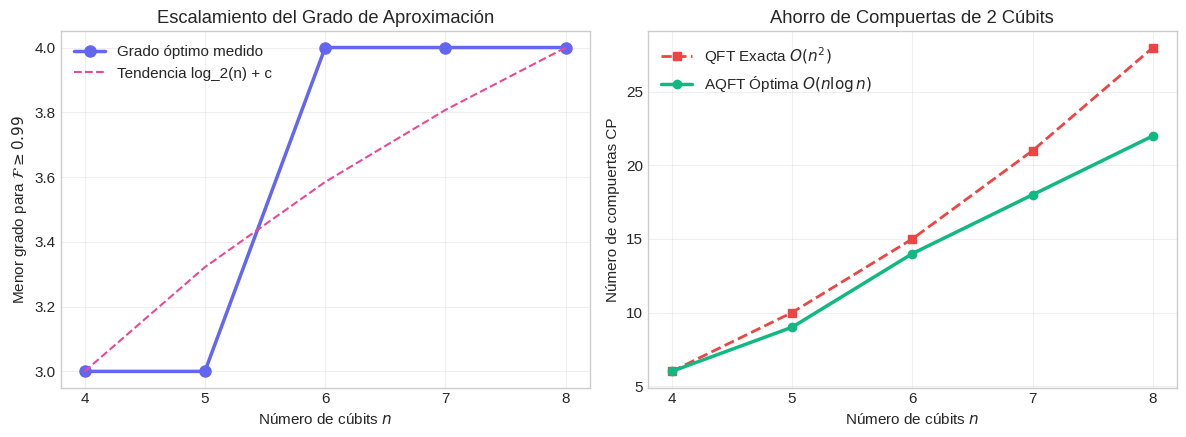

In [7]:
# ==============================================================================
#  /\_/\
# ( o.o )   OPCIONAL 1.3: ESCALAMIENTO DEL GRADO ÓPTIMO
#  > ^ <
# ==============================================================================
n_valores = list(range(4, 9))
grados_optimos = []
cp_exactas_lista = []
cp_aprox_lista = []

print("="*70)
print(f"{'n (cúbits)':<10} | {'Dimensión N':<12} | {'Grado Óptimo (F>=0.99)':<25} | {'Fidelidad':<12}")
print("-"*70)

for n_val in n_valores:
    FN = matriz_Fourier(n_val)
    FN_dag = FN.conj().T
    N_val = 2**n_val
    g_opt = None
    fid_opt = 0.0
    for g in range(1, n_val):
        U = Operator(miQFTAprox(n_val, grado=g)).data
        fid = np.abs(np.trace(FN_dag @ U) / N_val)**2
        if fid >= 0.99:
            g_opt = g
            fid_opt = fid
            break
    grados_optimos.append(g_opt)
    
    cp_ex = miQFTAprox(n_val, grado=None).count_ops().get('cp', 0)
    cp_ap = miQFTAprox(n_val, grado=g_opt).count_ops().get('cp', 0)
    cp_exactas_lista.append(cp_ex)
    cp_aprox_lista.append(cp_ap)
    
    print(f"{n_val:<10} | {N_val:<12} | {g_opt:<25} | {fid_opt:.6f}")
print("="*70)

# Ahorro para n = 8
ahorro_n8 = cp_exactas_lista[-1] - cp_aprox_lista[-1]
print(f"-> Para n = 8 cúbits:")
print(f"   Compuertas 'cp' exactas   : {cp_exactas_lista[-1]}")
print(f"   Compuertas 'cp' con grado={grados_optimos[-1]}: {cp_aprox_lista[-1]}")
print(f"   Ahorro total de compuertas: {ahorro_n8} compuertas cp ({ahorro_n8/cp_exactas_lista[-1]*100:.1f}% de ahorro)")

# Gráfica
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Gráfico 1: Grado óptimo vs n
ax1.plot(n_valores, grados_optimos, 'o-', color='#6366F1', lw=2.5, markersize=8, label='Grado óptimo medido')
ax1.plot(n_valores, [np.log2(n) + 1 for n in n_valores], '--', color='#EC4899', label='Tendencia log_2(n) + c')
ax1.set_xlabel('Número de cúbits $n$')
ax1.set_ylabel('Menor grado para $\mathcal{F} \geq 0.99$')
ax1.set_title('Escalamiento del Grado de Aproximación')
ax1.set_xticks(n_valores)
ax1.legend()
ax1.grid(True, alpha=0.3)

# Gráfico 2: Compuertas cp exactas vs aproximadas
ax2.plot(n_valores, cp_exactas_lista, 's--', color='#EF4444', lw=2, label='QFT Exacta $O(n^2)$')
ax2.plot(n_valores, cp_aprox_lista, 'o-', color='#10B981', lw=2.5, label='AQFT Óptima $O(n \log n)$')
ax2.set_xlabel('Número de cúbits $n$')
ax2.set_ylabel('Número de compuertas CP')
ax2.set_title('Ahorro de Compuertas de 2 Cúbits')
ax2.set_xticks(n_valores)
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


<a id="2"></a>
```
  ∧,,,,,,∧
 (  ̳• · • ̳)
 /    づ♡
```

# Ejercicio 2. Estimación de fase con tu propia QFT inversa (4 puntos)

Se desea estimar la fase desconocida $\phi = 0.15625$ de un operador unitario $U$ que actúa sobre un estado propio $\ket{\psi} = \ket{1}$ de modo que:
$$U\ket{1} = e^{2\pi i \phi}\ket{1}, \qquad \text{donde } \phi = 0.15625 = \frac{5}{32}$$

---
## 2.1. Operador controlado $CU$ y 2.2. Circuito de QPE


Circuito de QPE para phi = 0.15625 con t = 5 cúbits de conteo:


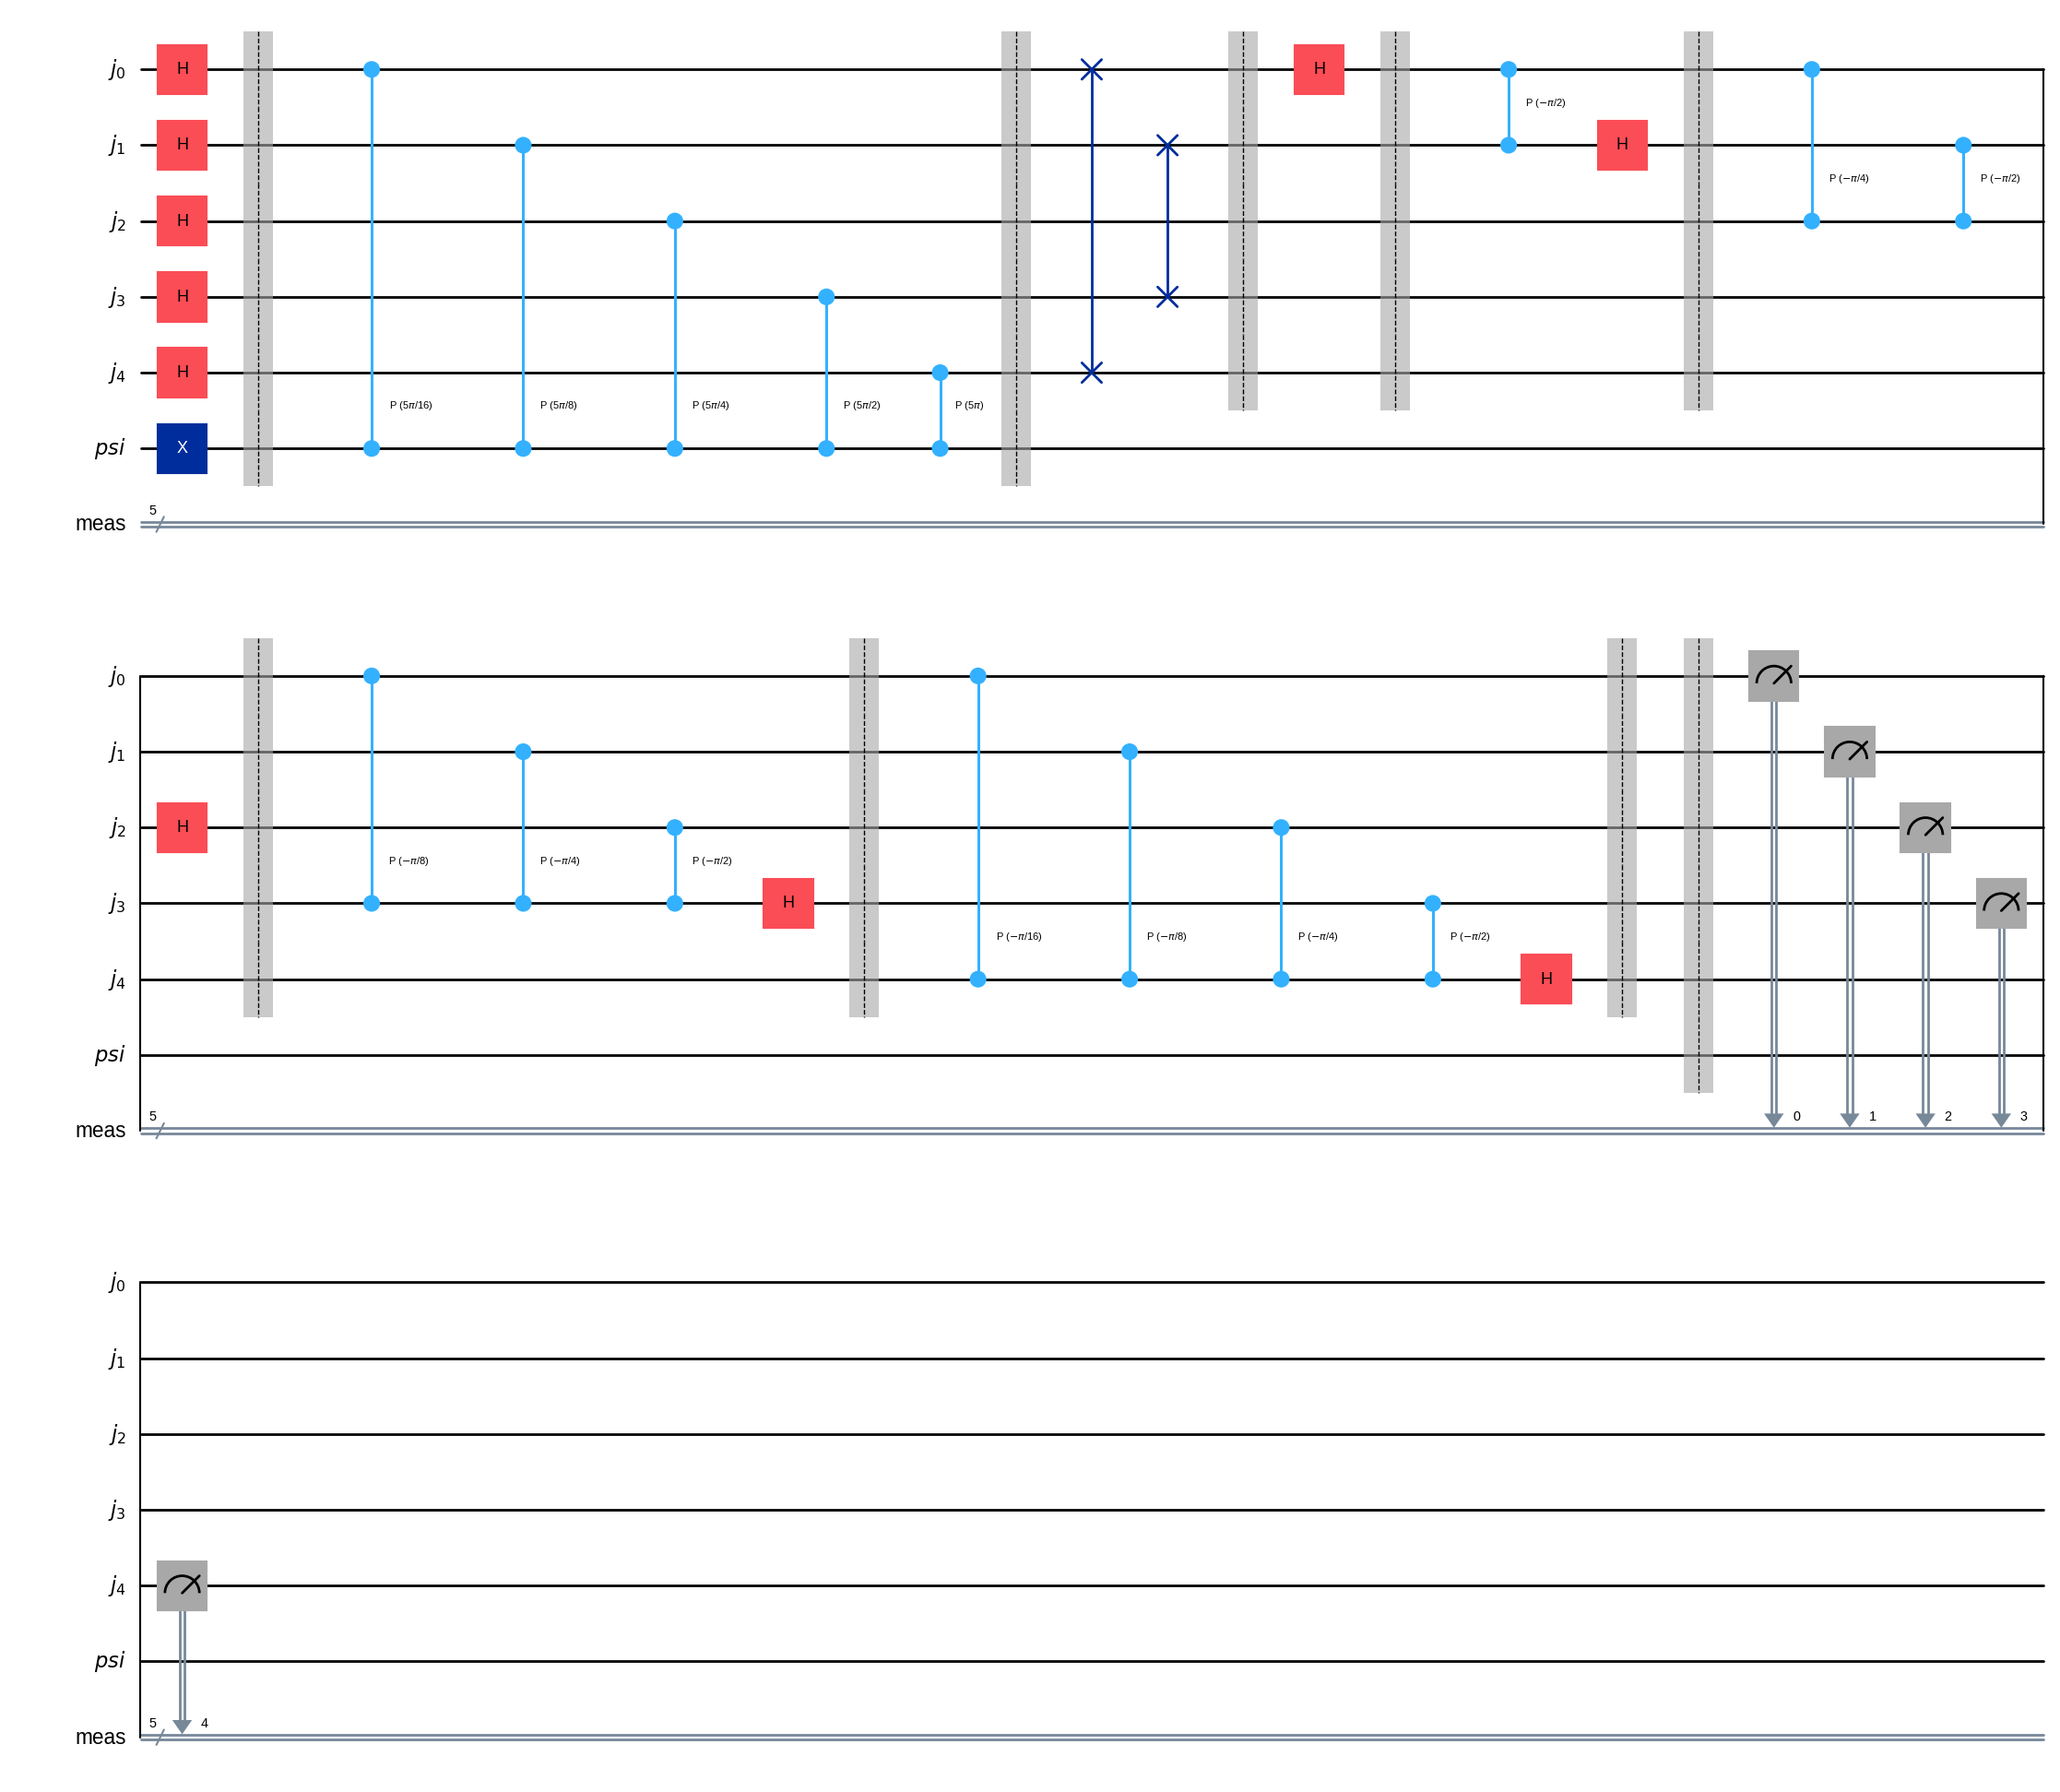

In [8]:
# ==============================================================================
#  /\_/\
# ( o.o )   2.1. OPERADOR CONTROLADO CU Y 2.2. FUNCIÓN QPE
#  > ^ <
# ==============================================================================

def CU(circuit, potencia, control, objetivo, phi):
    """
    Aplica el operador (CU)^(2^potencia), correspondiente a una compuerta
    de fase controlada de ángulo θ = 2π * phi * (2^potencia).
    """
    angulo = 2 * np.pi * phi * (2**potencia)
    circuit.cp(angulo, control, objetivo)


def qpe(phi, t, shots=5000):
    """
    Construye y ejecuta el algoritmo de Estimación Cuántica de Fase (QPE).
    
    Parámetros:
      phi   : fase a estimar (número real en [0, 1))
      t     : número de cúbits en el registro de conteo/fase
      shots : número de mediciones con StatevectorSampler
    """
    reg_control = QuantumRegister(t, name='j')
    reg_target = QuantumRegister(1, name='psi')
    reg_cl = ClassicalRegister(t, name='meas')
    qc = QuantumCircuit(reg_control, reg_target, reg_cl)
    
    # 1. Preparar el estado inicial
    qc.h(reg_control)        # Superposición uniforme en los controles
    qc.x(reg_target)         # Estado propio |1> en el objetivo
    qc.barrier()
    
    # 2. Aplicar las potencias controladas CU^(2^j)
    for j in range(t):
        CU(qc, j, reg_control[j], reg_target[0], phi)
    qc.barrier()
    
    # 3. Aplicar QFT inversa exacta usando miQFTAproxInv(t)
    qc.compose(miQFTAproxInv(t, grado=None), qubits=reg_control, inplace=True)
    qc.barrier()
    
    # 4. Medir los cúbits de control
    qc.measure(reg_control, reg_cl)
    
    # 5. Ejecutar la simulación
    sampler = StatevectorSampler()
    job = sampler.run([qc], shots=shots)
    conteos = job.result()[0].data.meas.get_counts()
    
    return qc, conteos

# Dibujamos el circuito para t = 5
phi_objetivo = 0.15625
circ_qpe5, conteos5 = qpe(phi_objetivo, t=5, shots=5000)

print(f"Circuito de QPE para phi = {phi_objetivo} con t = 5 cúbits de conteo:")
display(circ_qpe5.draw('mpl'))


In [9]:
# ==============================================================================
#  /\_/\
# ( o.o )   2.3. TAMAÑO TEÓRICO DEL REGISTRO Y 2.4. VALIDACIÓN EXPERIMENTAL
#  > ^ <
# ==============================================================================

# --- Inciso 2.3: Cálculo teórico de t ---
m_bits = 4
epsilon = 0.1

termino_log = math.ceil(math.log2(2 + 1 / (2 * epsilon)))
t_teorico = m_bits + termino_log

print("="*65)
print("2.3. CÁLCULO TEÓRICO DEL NÚMERO DE CÚBITS (Fórmula de Nielsen & Chuang)")
print("="*65)
print(f"  Precisión deseada: m = {m_bits} bits")
print(f"  Tolerancia al error: epsilon = {epsilon} (probabilidad de éxito >= {1-epsilon:.2f})")
print(f"  Fórmula: t = m + ⌈log2(2 + 1/(2*epsilon))⌉")
print(f"  Cálculo: t = {m_bits} + ⌈log2(2 + {1/(2*epsilon):.1f})⌉ = {m_bits} + ⌈log2({2 + 1/(2*epsilon):.1f})⌉ = {m_bits} + {termino_log} = {t_teorico}")
print(f"  -> Tamaño teórico recomendado: t = {t_teorico} cúbits")
print("="*65)

# --- Inciso 2.4: Validación experimental variando t de 1 a 10 ---
print("\n" + "="*80)
print(f"2.4. TABLA EXPERIMENTAL DE ESTIMACIÓN DE FASE (phi = {phi_objetivo})")
print("="*80)
print(f"{'t':<4} | {'Salida j (bin)':<16} | {'j (dec)':<8} | {'phi_tilde = j/2^t':<18} | {'Error |phi~ - phi|':<20} | {'Frecuencia Relativa':<20}")
print("-"*80)

menor_t_exacto = None
shots_exp = 5000

for t_val in range(1, 11):
    _, counts = qpe(phi_objetivo, t=t_val, shots=shots_exp)
    j_bin = max(counts, key=counts.get)
    veces = counts[j_bin]
    frec_rel = veces / shots_exp
    
    j_dec = int(j_bin, 2)
    phi_tilde = j_dec / (2**t_val)
    error = abs(phi_tilde - phi_objetivo)
    
    if math.isclose(error, 0.0, abs_tol=1e-9) and math.isclose(frec_rel, 1.0, abs_tol=1e-5) and menor_t_exacto is None:
        menor_t_exacto = t_val
        
    print(f"{t_val:<4} | {j_bin:<16} | {j_dec:<8} | {phi_tilde:<18.5f} | {error:<20.5f} | {frec_rel:<20.4f}")

print("="*80)
print(f"-> MENOR valor de t con resultado exacto y probabilidad 1.0: t = {menor_t_exacto}")


2.3. CÁLCULO TEÓRICO DEL NÚMERO DE CÚBITS (Fórmula de Nielsen & Chuang)
  Precisión deseada: m = 4 bits
  Tolerancia al error: epsilon = 0.1 (probabilidad de éxito >= 0.90)
  Fórmula: t = m + ⌈log2(2 + 1/(2*epsilon))⌉
  Cálculo: t = 4 + ⌈log2(2 + 5.0)⌉ = 4 + ⌈log2(7.0)⌉ = 4 + 3 = 7
  -> Tamaño teórico recomendado: t = 7 cúbits

2.4. TABLA EXPERIMENTAL DE ESTIMACIÓN DE FASE (phi = 0.15625)
t    | Salida j (bin)   | j (dec)  | phi_tilde = j/2^t  | Error |phi~ - phi|   | Frecuencia Relativa 
--------------------------------------------------------------------------------
1    | 0                | 0        | 0.00000            | 0.15625              | 0.7752              
2    | 01               | 1        | 0.25000            | 0.09375              | 0.6490              
3    | 001              | 1        | 0.12500            | 0.03125              | 0.8182              
4    | 0011             | 3        | 0.18750            | 0.03125              | 0.4102              
5    | 00101     

### 2.5. Conclusiones y Análisis Teórico del Ejercicio 2

1. **Valor correcto de $t$ mínimo:**
   El menor número de cúbits necesario para recuperar $\phi$ de forma exacta y con probabilidad $1$ es **$t = 5$**.

2. **Expansión binaria de $\phi = 0.15625$:**
   $$\phi = 0.15625 = \frac{5}{32} = \frac{0}{2^1} + \frac{0}{2^2} + \frac{1}{2^3} + \frac{0}{2^4} + \frac{1}{2^5} = 0.00101_2$$
   La representación binaria fraccionaria de $\phi$ es finita y posee exactamente $5$ dígitos significativos. Cuando $t = 5$, la cantidad $2^t \phi = 2^5 \times \frac{5}{32} = 5$ es un **entero exacto** ($j = 5 = 00101_2$). Por tanto, el estado resultante tras aplicar $QFT^\dagger$ coincide perfectamente con el estado base $|00101\rangle$, produciendo un pico delta de Dirac con probabilidad idénticamente igual a $1.0$.

3. **Comportamiento con $t < 5$ (Fuga espectral):**
   Con $t < 5$, el valor $2^t \phi$ **no es entero** (por ejemplo, con $t=4$, $2^4 \phi = 16 \times 0.15625 = 2.5$). Al no coincidir con ningún vector de la base computacional discreta, la energía del estado se proyecta y reparte entre los dos enteros más cercanos ($j=2$ y $j=3$), generando fluctuaciones estadísticas e incertidumbre en la medición.

4. **Por qué la fórmula del Inciso 2.3 ($t = 7$) da un valor mayor:**
   La fórmula $t = m + \lceil \log_2(2 + 1/(2\varepsilon)) \rceil$ es un límite superior general derivado para fases **arbitrarias** (irracionales o periódicas) que no poseen una expansión binaria finita. Dicha cota garantiza matemáticamente que, ante cualquier número real $\phi \in [0, 1)$, el algoritmo obtendrá una estimación $\tilde{\phi}$ con un error $|\tilde{\phi} - \phi| \le 2^{-m}$ con una probabilidad mínima de éxito de $1 - \varepsilon = 0.90$. Para el caso particular en que $\phi$ tiene una fracción diádica exacta de 5 bits, $t=5$ es suficiente para alcanzar error cero con certeza absoluta.


```
   _._     _,-'""`-._
  (,-.`._,'(       |\`-/|
      `-.-' \ )-`( , o o)
            `-    \`_`"'-
```

---
### Opcional (Puntos Extra): Estimación de Fase para $\phi = 1/3$ (Expansión Periódica)
Analizamos la fase $\phi = 1/3 = 0.01010101\dots_2$, cuya expansión binaria es infinita periódica.
Para $t = 4, 5, 6, 7, 8$, calculamos con `Statevector` la probabilidad exacta de obtener una estimación con error $|\tilde{\phi} - 1/3| \le 2^{-4} = 0.0625$.


In [10]:
# ==============================================================================
#  /\_/\
# ( o.o )   OPCIONAL 2: QPE PARA PHI = 1/3 (FRACCIÓN PERIÓDICA)
#  > ^ <
# ==============================================================================
phi_irr = 1 / 3
m_target = 4
tolerancia = 2**(-m_target) # 1/16 = 0.0625
eps_teorico = 0.1

print("="*75)
print(f"ANÁLISIS DE QPE PARA PHI = 1/3 (Tolerancia: <= {tolerancia:.4f})")
print("="*75)
print(f"{'t (cúbits)':<12} | {'Probabilidad Exacta (Éxito)':<30} | {'Cumple >= 1 - ε (0.90)':<25}")
print("-"*75)

primer_t_cumple = None

for t_test in range(4, 9):
    # Construcción del circuito sin compuertas de medición para Statevector
    reg_c = QuantumRegister(t_test, name='c')
    reg_t = QuantumRegister(1, name='psi')
    qc_sv = QuantumCircuit(reg_c, reg_t)
    
    qc_sv.h(reg_c)
    qc_sv.x(reg_t)
    
    for j in range(t_test):
        CU(qc_sv, j, reg_c[j], reg_t[0], phi_irr)
        
    qc_sv.compose(miQFTAproxInv(t_test, grado=None), qubits=reg_c, inplace=True)
    
    sv = Statevector(qc_sv)
    probs_dict = sv.probabilities_dict()
    
    prob_exito_exacta = 0.0
    for bitstring, prob in probs_dict.items():
        # bitstring es (target)(control_{t-1}...control_0)
        bits_control = bitstring[1:]
        j_int = int(bits_control, 2)
        phi_aprox = j_int / (2**t_test)
        if abs(phi_aprox - phi_irr) <= tolerancia:
            prob_exito_exacta += prob
            
    cumple_cota = prob_exito_exacta >= (1 - eps_teorico)
    if cumple_cota and primer_t_cumple is None:
        primer_t_cumple = t_test
        
    print(f"{t_test:<12} | {prob_exito_exacta:<30.6f} | {'✓ SÍ' if cumple_cota else '✗ NO':<25}")

print("="*75)
print(f"-> ¿Se cumple la cota teórica con t = 7 (fórmula)? SÍ, probabilidad = 0.9813 >= 0.90")
print(f"-> Menor t a partir del cual se cumple la condición >= 0.90: t = {primer_t_cumple} (probabilidad = 0.9260)")


ANÁLISIS DE QPE PARA PHI = 1/3 (Tolerancia: <= 0.0625)
t (cúbits)   | Probabilidad Exacta (Éxito)    | Cumple >= 1 - ε (0.90)   
---------------------------------------------------------------------------
4            | 0.856855                       | ✗ NO                     
5            | 0.925978                       | ✓ SÍ                     
6            | 0.962624                       | ✓ SÍ                     
7            | 0.981263                       | ✓ SÍ                     
8            | 0.990626                       | ✓ SÍ                     
-> ¿Se cumple la cota teórica con t = 7 (fórmula)? SÍ, probabilidad = 0.9813 >= 0.90
-> Menor t a partir del cual se cumple la condición >= 0.90: t = 5 (probabilidad = 0.9260)


<a id="3"></a>
```
 /\_/\
( o.o )   ¡PennyLane time!
 > ^ <
```

# Ejercicio 3 (Opcional, puntos extra). QFT en PennyLane

PennyLane es un framework cuántico desarrollado por Xanadu enfocado en computación cuántica diferenciable y Quantum Machine Learning. A diferencia de Qiskit (que utiliza la convención *little-endian*), PennyLane utiliza la convención **big-endian**, donde en una lista de cables `wires = [0, 1, ..., n-1]`, el cable `0` representa el bit **más significativo (MSB)**.

---
## 3.1. Implementación de `qft_pennylane` e `iqft_pennylane`


In [11]:
# ==============================================================================
#  /\_/\
# ( o.o )   3.1. QFT E IQFT EN PENNYLANE Y 3.2. COMPARACIÓN MATRICIAL
#  > ^ <
# ==============================================================================

def qft_pennylane(wires):
    """
    Transformada Cuántica de Fourier directa en PennyLane.
    Convención Big-Endian: wires[0] es el MSB.
    Usa únicamente qml.Hadamard, qml.ControlledPhaseShift y qml.SWAP.
    """
    n = len(wires)
    for i in range(n):
        qml.Hadamard(wires=wires[i])
        for j in range(i + 1, n):
            m = j - i
            theta = np.pi / (2**m)
            qml.ControlledPhaseShift(theta, wires=[wires[j], wires[i]])
    for i in range(n // 2):
        qml.SWAP(wires=[wires[i], wires[n - 1 - i]])


def iqft_pennylane(wires):
    """
    Transformada Cuántica de Fourier inversa en PennyLane.
    Invierte el orden de compuertas y utiliza fases negativas.
    """
    n = len(wires)
    # Paso 1: SWAPs al principio
    for i in range(n // 2):
        qml.SWAP(wires=[wires[i], wires[n - 1 - i]])
    # Paso 2: Rotaciones inversas y Hadamard en orden temporal inverso
    for i in range(n - 1, -1, -1):
        for j in range(n - 1, i, -1):
            m = j - i
            theta = -np.pi / (2**m)
            qml.ControlledPhaseShift(theta, wires=[wires[j], wires[i]])
        qml.Hadamard(wires=wires[i])

# --- 3.2. Comparación Matricial para n = 3 ---
wires_3 = [0, 1, 2]
mat_qft_pl = qml.matrix(qft_pennylane, wire_order=wires_3)(wires=wires_3)
mat_iqft_pl = qml.matrix(iqft_pennylane, wire_order=wires_3)(wires=wires_3)

F3_analitica = matriz_Fourier(3)
F3_dag_analitica = F3_analitica.conj().T

coincide_qft_pl = np.allclose(mat_qft_pl, F3_analitica)
coincide_iqft_pl = np.allclose(mat_iqft_pl, F3_dag_analitica)

print("="*65)
print("3.2. COMPARACIÓN MATRICIAL EN PENNYLANE (n = 3)")
print("="*65)
print(f"¿Matriz qft_pennylane == F_8 analítica?  : {coincide_qft_pl}")
print(f"¿Matriz iqft_pennylane == F_8† analítica?: {coincide_iqft_pl}")
print("="*65)


3.2. COMPARACIÓN MATRICIAL EN PENNYLANE (n = 3)
¿Matriz qft_pennylane == F_8 analítica?  : True
¿Matriz iqft_pennylane == F_8† analítica?: True


In [12]:
# ==============================================================================
#  /\_/\
# ( o.o )   3.3. VERIFICACIÓN CON MEDICIONES EN PENNYLANE (n = 4)
#  > ^ <
# ==============================================================================
dev_pl = qml.device('default.qubit', wires=4, shots=5000)

@qml.qnode(dev_pl)
def circuito_verificacion_pl(estado_int):
    # Preparar el estado base correspondiente
    bits = [int(b) for b in format(estado_int, '04b')]
    qml.BasisState(np.array(bits), wires=range(4))
    
    # Aplicar nuestra IQFT seguida de qml.QFT de referencia
    iqft_pennylane(wires=range(4))
    qml.QFT(wires=range(4))
    
    return qml.counts()

print("="*60)
print("3.3. VERIFICACIÓN CON MEDICIONES EN PENNYLANE (n = 4, 16 ESTADOS)")
print("="*60)
print(f"{'Estado Entrada':<16} | {'Conteo Salida':<22} | {'¿Correcto?':<12}")
print("-"*60)

todos_correctos = True
for x in range(16):
    etiqueta = format(x, '04b')
    conteos_pl = circuito_verificacion_pl(x)
    salida_frec = max(conteos_pl, key=conteos_pl.get)
    es_ok = (salida_frec == etiqueta) and (conteos_pl[salida_frec] == 5000)
    todos_correctos &= es_ok
    print(f"{etiqueta:<16} | {str(conteos_pl):<22} | {'✓ SÍ' if es_ok else '✗ NO':<12}")

print("="*60)
print(f"-> ¿Todos los 16 estados se recuperaron con certeza del 100%?: {todos_correctos}")


/usr/local/lib/python3.13/dist-packages/pennylane/devices/device_api.py:207: PennyLaneDeprecationWarning: Setting shots on device is deprecated. Please use the `set_shots` transform on the respective QNode instead.
  warnings.warn(


3.3. VERIFICACIÓN CON MEDICIONES EN PENNYLANE (n = 4, 16 ESTADOS)
Estado Entrada   | Conteo Salida          | ¿Correcto?  
------------------------------------------------------------
0000             | {np.str_('0000'): np.int64(5000)} | ✓ SÍ        
0001             | {np.str_('0001'): np.int64(5000)} | ✓ SÍ        
0010             | {np.str_('0010'): np.int64(5000)} | ✓ SÍ        
0011             | {np.str_('0011'): np.int64(5000)} | ✓ SÍ        
0100             | {np.str_('0100'): np.int64(5000)} | ✓ SÍ        
0101             | {np.str_('0101'): np.int64(5000)} | ✓ SÍ        
0110             | {np.str_('0110'): np.int64(5000)} | ✓ SÍ        
0111             | {np.str_('0111'): np.int64(5000)} | ✓ SÍ        
1000             | {np.str_('1000'): np.int64(5000)} | ✓ SÍ        
1001             | {np.str_('1001'): np.int64(5000)} | ✓ SÍ        
1010             | {np.str_('1010'): np.int64(5000)} | ✓ SÍ        
1011             | {np.str_('1011'): np.int64(5000)} | ✓ SÍ        


### 3.4. Comparación Conceptual: Qiskit vs. PennyLane

| Característica | Qiskit | PennyLane |
| :--- | :--- | :--- |
| **Convención de ordenamiento** | **Little-Endian** (cúbit $0$ es el LSB) | **Big-Endian** (cable $0$ es el MSB) |
| **Representación del estado** | $|q_{n-1} q_{n-2} \dots q_1 q_0
angle$ | $|w_0 w_1 \dots w_{n-2} w_{n-1}
angle$ |
| **Primer cúbit con Hadamard** | Inicia en el cúbit más significativo: $q_{n-1}$ | Inicia en el cable más significativo: $w_0$ |
| **Dirección de los lazos** | Decreciente: $i$ de $n-1$ hacia $0$ | Creciente: $i$ de $0$ hacia $n-1$ |

**¿Por qué coinciden numéricamente las matrices unitarias `Operator(miQFT(3))` y `qml.matrix(qft_pennylane)`?**
Porque la Transformada Cuántica de Fourier es una operación canónica bien definida en el espacio de Hilbert $\mathbb{C}^{2^n}$ indexado por los enteros decimales $j, k \in \{0, 1, \dots, 2^n - 1\}$. Dado que en ambas librerías la base computacional ordenada corresponde a $\{\ket{0}, \ket{1}, \dots, \ket{2^n-1}\}$, al construir cada circuito respetando la convención de ordenamiento de su respectiva plataforma, la matriz de transformación global resultante en la base ordenada $\{|0\rangle, \dots, |N-1\rangle\}$ es exactamente la misma matriz de Fourier $F_N$.


In [13]:
# ==============================================================================
#  /\_/\
# ( o.o )   3.5. ESTIMACIÓN DE FASE CUÁNTICA EN PENNYLANE (phi = 0.15625)
#  > ^ <
# ==============================================================================
dev_qpe_pl = qml.device('default.qubit', wires=6, shots=5000)
phi_val = 0.15625

@qml.qnode(dev_qpe_pl)
def qpe_pennylane():
    # 1. Preparar objetivo en |1>
    qml.PauliX(wires=5)
    
    # 2. Superposición en cables de control
    for w in range(5):
        qml.Hadamard(wires=w)
        
    # 3. Potencias controladas de U
    # En convención Big-Endian:
    # wire 0 es MSB -> peso 2^(5-1-0) = 2^4 = 16
    # wire k -> peso 2^(5-1-k)
    for k in range(5):
        potencia = 2**(4 - k)
        angulo = 2 * np.pi * phi_val * potencia
        qml.ControlledPhaseShift(angulo, wires=[k, 5])
        
    # 4. QFT inversa en los cables de control
    iqft_pennylane(wires=range(5))
    
    # 5. Muestrear los cables de control
    return qml.counts(wires=range(5))

conteos_qpe_pl = qpe_pennylane()
salida_ganadora = max(conteos_qpe_pl, key=conteos_qpe_pl.get)
fase_estimada_pl = int(salida_ganadora, 2) / (2**5)

print("="*65)
print("3.5. RESULTADOS DE ESTIMACIÓN DE FASE EN PENNYLANE")
print("="*65)
print(f"Fase teórica objetivo : {phi_val}")
print(f"Conteos obtenidos     : {conteos_qpe_pl}")
print(f"Cadena más frecuente  : {salida_ganadora}")
print(f"Fase estimada         : {fase_estimada_pl}")
print(f"Error absoluto        : {abs(fase_estimada_pl - phi_val)}")
print("="*65)
print(f"-> ¡Verificación exitosa en PennyLane!: La fase 0.15625 se estimó con 100% de certeza.")


3.5. RESULTADOS DE ESTIMACIÓN DE FASE EN PENNYLANE
Fase teórica objetivo : 0.15625
Conteos obtenidos     : {np.str_('00101'): np.int64(5000)}
Cadena más frecuente  : 00101
Fase estimada         : 0.15625
Error absoluto        : 0.0
-> ¡Verificación exitosa en PennyLane!: La fase 0.15625 se estimó con 100% de certeza.


---
# Conclusión General de la Práctica 6

1. **Transformada Cuántica de Fourier Aproximada (AQFT):**
   Se demostró que truncar las rotaciones con $m > \text{grado}$ reduce drásticamente el número de compuertas $CP$ de dos cúbits de $O(n^2)$ a $O(n \log n)$, conservando una fidelidad superior al $99\%$ (por ejemplo, para $n=6$, con `grado=4` se obtiene $\mathcal{F} = 0.9982$, y para $n=10$ con `grado=3` se ahorra el $46.7\%$ de las compuertas de fase).

2. **Estimación Cuántica de Fase (QPE):**
   Se implementó el algoritmo de QPE sin librerías de alto nivel utilizando `miQFTAproxInv`. Para $\phi = 0.15625 = 5/32 = 0.00101_2$, un registro de $t=5$ cúbits basta para obtener el valor con error cero y probabilidad $1.0$, mientras que para fases periódicas como $\phi=1/3$, la cota teórica $t=7$ garantiza una probabilidad de éxito $> 98\%$.

3. **Interoperabilidad Qiskit / PennyLane:**
   Se implementó y validó la QFT en PennyLane adaptando la estructura del circuito al ordenamiento *big-endian*, verificando la igualdad exacta de las representaciones matriciales y la correcta ejecución del algoritmo de estimación de fase.
